#### General Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
os.chdir('D:\Machine Learning\Datasets')
import warnings
warnings.filterwarnings('ignore')
import matplotlib

#### Sklearn Imports

In [2]:
from sklearn.ensemble import RandomForestRegressor

##### Sktime imports

In [17]:
import sktime
from sktime.forecasting.compose import make_reduction
from sktime.forecasting.model_selection import ForecastingGridSearchCV, temporal_train_test_split
from sktime.performance_metrics.forecasting import MeanSquaredError
from sktime.utils.plotting import plot_series
from statsmodels.graphics.tsaplots import plot_pacf, plot_acf
from sktime.split import SlidingWindowSplitter

* Time indexing is mandatory to use sktime

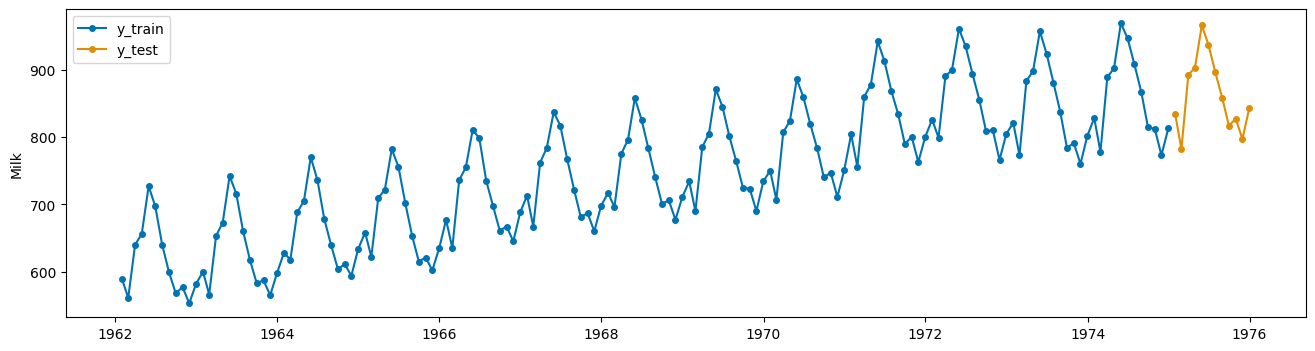

In [4]:
df = pd.read_csv("monthly-milk-production-pounds-p.csv", index_col=0)
df.index = pd.date_range(start='1962-01-01', periods=len(df), freq='ME')
y = df['Milk']
y_train, y_test = temporal_train_test_split(y, test_size=12)
plot_series(y_train, y_test, labels=["y_train", 'y_test'])
plt.legend()
plt.show()

In [13]:
fh = np.arange(1, len(y_test) + 1) # Forecasting Horizon
regressor = RandomForestRegressor(random_state=25)
forecastor = make_reduction(regressor, window_length=10)
forecastor.fit(y_train)
y_pred = forecastor.predict(fh)
rmse = MeanSquaredError(square_root=True)
rmse(y_test, y_pred)

d:\Anaconda\envs\sktime-env\Lib\site-packages\sktime\forecasting\base\_fh.py:863: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  return r * to_offset(fh.freq)
d:\Anaconda\envs\sktime-env\Lib\site-packages\sktime\forecasting\base\_fh.py:877: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  absolute = pd.DatetimeIndex(absolute, freq=fh.freq)


np.float64(71.45569373161713)

#### Basic Grid Search

We fit the forecaster on an intial window which is 80% of the historical data then use temoral sliding window cross-validation to find the optimal hyper-parameters

In [22]:
regressor = RandomForestRegressor(random_state=25)
forecastor = make_reduction(regressor, strategy="recursive")
param_grid = {"window_length": [7,10,12,15]}
cv = SlidingWindowSplitter(initial_window = int(len(y_train) * 0.8), window_length=8)
gscv = ForecastingGridSearchCV(forecastor, strategy='refit', cv=cv, scoring=rmse, param_grid=param_grid)
gscv.fit(y_train)
print(gscv.best_params_)
print(gscv.best_score_)

{'window_length': 7}
41.07625


#### Gradient Boosting Regressor

In [27]:
from sklearn.ensemble import GradientBoostingRegressor
regressor = GradientBoostingRegressor(random_state=25)
forecastor = make_reduction(regressor, window_length=15, strategy="recursive")
param_grid = { "window_length": [7,10,12,15],
              'estimator__n_estimators': [50,100,150],
              'estimator__learning_rate':np.linspace(0.01,0.2,5),
              'estimator__max_depth': [3,4,5,6] }
cv = SlidingWindowSplitter(initial_window=int(len(y_train) * 0.8), window_length=24)
gscv = ForecastingGridSearchCV(forecastor, strategy='refit', cv=cv, scoring=rmse, param_grid=param_grid)
gscv.fit(y_train)
print(gscv.best_params_)
print(gscv.best_score_)

{'estimator__learning_rate': np.float64(0.15250000000000002), 'estimator__max_depth': 3, 'estimator__n_estimators': 150, 'window_length': 12}
16.574283153251127
